In [2]:
import pandas as pd
import numpy as np
from math import pi
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from scipy.optimize import root_scalar

# Obtain the initial guess

In [3]:
# loading excel data
excel_file = '/Users/wangyimin/Downloads/viscosity.xlsx'
df = pd.read_excel(excel_file,sheet_name='Sheet2')

df.dropna(subset=["Concentration", "Shear rate (1/s)", "Viscosity (Pa.s)"], inplace=True)

df = df[(df["Concentration"] > 0) & 
        (df["Shear rate (1/s)"] > 0) & 
        (df["Viscosity (Pa.s)"] > 0)]

# Take the logarithm
df["lnVisc"]  = np.log(df["Viscosity (Pa.s)"])
df["lnConc"]  = np.log(df["Concentration"])
df["lnGamma"] = np.log(df["Shear rate (1/s)"])

# Define model functions
def powerlaw_viscosity_exp(C_gamma, A, beta2, n):
    C, gamma = C_gamma
    return A * np.exp(beta2 * C) * (gamma ** (n - 1))

# Extract data
C_data = df["Concentration"].values
gamma_data = df["Shear rate (1/s)"].values
eta_data = df["Viscosity (Pa.s)"].values

# Fitting
popt, pcov = curve_fit(powerlaw_viscosity_exp, (C_data, gamma_data), eta_data, p0=(1e-4, 0.01, 0.5))
A_fit, beta2_fit, n_fit = popt

print("Nonlinear fitting result (exponential concentration term):")
print("A =", A_fit)
print("beta2 =", beta2_fit)
print("n =", n_fit)

Nonlinear fitting result (exponential concentration term):
A = 0.0024627017686526032
beta2 = 0.04295972418815393
n = 0.5733665177034247


# Modeling

[[  50.     70.     60.     70.     90.     80.  ]
 [1500.   2400.   1800.   2100.   1800.   1500.  ]
 [  10.18   10.18   10.18   10.18   10.18   10.18]]
Fitted parameters:
A = 344069893015482.9
beta2 = 0.028851604739251472
n = -0.6781958157849525
[ 331.06402871 1685.02744     345.98854598  237.13731522  126.19562241
 1384.00469444  115.5414663   657.87652778  203.31782727  263.90804244
 1261.17824444  451.96534524  102.86155043  103.71004467  778.19970103
  722.78466667  134.24190073  223.58281046  183.03176712  239.22045113
  633.48442029  487.24054167  524.23087903  343.41650282]
[ 371.00629522 1790.81627998  408.40371642  285.61163522  156.12717329
 1341.99255501  160.3888011   617.14369629  171.86478673  259.70691618
 1098.97585775  508.60163311   87.67517515  116.99776606  753.61277497
  727.26307869  120.19132246  229.34423659  208.343245    278.02276069
  544.99260926  564.7384071   462.47192135  381.13323669]
[ 375.55350732  180.47461099  271.87038147  247.76522727  900.236411

/var/folders/3j/t2dldl5s4cvfdpp3j56t73680000gn/T/ipykernel_18708/3553783552.py:7: RuntimeWarning: overflow encountered in multiply
  Dp_pred = A * np.exp(beta2 * conc) * ((pi * Dc * N)**(n-2))


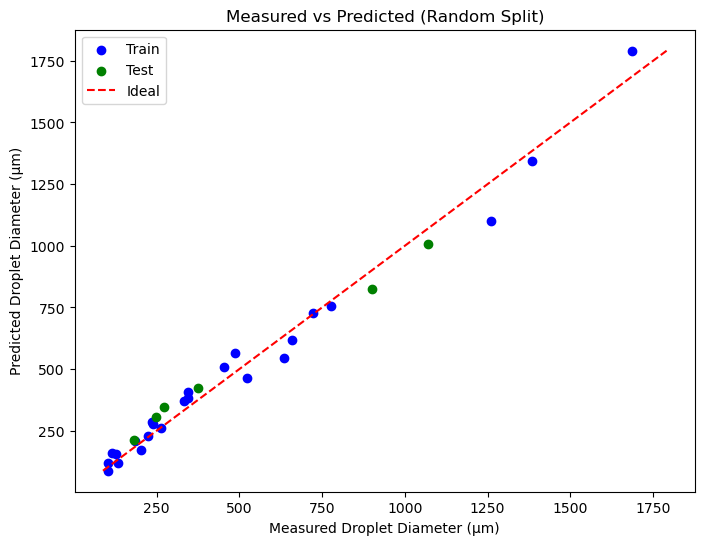

In [4]:
# ========= define model =========
def model_func(X, A, beta2, n):
    conc = X[0]  # BME concentration
    N = X[1]     # rotational speed (RPM)
    Dc = X[2]    # centrifuge tube diameter (mm)
    # Model formula
    Dp_pred = A * np.exp(beta2 * conc) * ((pi * Dc * N)**(n-2))
    return Dp_pred

# ========= loading data =========
df = pd.read_excel("/Users/wangyimin/Downloads/Figure1f-BEM%-vortex -speed-delete red.xlsx", sheet_name='Sheet1')
Dp_exp = df["Mean droplet diameter(μm)"].values
conc   = df["%BME"].values
N      = df["Rotational speed(rpm)"].values
Dc     = df["Container diameter(mm)"].values

X_all = np.vstack([conc, N, Dc])  # Combination of independent variables

# ========= Random split training/test 8:2 ========= 
"""
Datasets: 24 droplets generation cases from 2ml centrifuge tube 
training data: using for fitting the constant (19 samples)
testing data: internal validation set (5 samples)
""" #26
X_train, X_test, y_train, y_test = train_test_split(
    X_all.T, Dp_exp, test_size=0.2, random_state= 32
)
#  curve_fit aquire X shape as (n_features, n_samples)
X_train = X_train.T
X_test  = X_test.T
print(X_test)


# ========= fitting =========
initial_guess = [1, 0.04295972418815393, 0.5733665177034247]
popt, pcov = curve_fit(model_func, X_train, y_train, p0=initial_guess, maxfev=10000)
A_fit, beta2_fit, n_fit = popt

print("Fitted parameters:")
print("A =", A_fit)
print("beta2 =", beta2_fit)
print("n =", n_fit)

# ========= predict =========
y_train_pred = model_func(X_train, *popt)
y_test_pred  = model_func(X_test, *popt)

print(y_train)
print(y_train_pred)


print(y_test)
print(y_test_pred)


# ========= R^2 and Pearson =========
def r2_score(y, y_pred):
    ss_res = np.sum((y - y_pred)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    return 1 - ss_res/ss_tot

print("Training R^2 =", r2_score(y_train, y_train_pred))
print("Testing  R^2 =", r2_score(y_test, y_test_pred))

r_value_train, p_value_train = pearsonr(y_train, y_train_pred)
r_value_test,  p_value_test  = pearsonr(y_test, y_test_pred)
print("Train Pearson r =", r_value_train, "p =", p_value_train)
print("Test  Pearson r =", r_value_test, "p =", p_value_test)

# ========= figure =========
plt.figure(figsize=(8,6))
plt.scatter(y_train, y_train_pred, color='blue', label="Train")
plt.scatter(y_test, y_test_pred, color='green', label="Test")
all_min = min(Dp_exp.min(), y_train_pred.min(), y_test_pred.min())
all_max = max(Dp_exp.max(), y_train_pred.max(), y_test_pred.max())
plt.plot([all_min, all_max], [all_min, all_max], 'r--', label="Ideal")
plt.xlabel("Measured Droplet Diameter (μm)")
plt.ylabel("Predicted Droplet Diameter (μm)")
plt.legend()
plt.title("Measured vs Predicted (Random Split)")
plt.show()


# Prediction

In [69]:
# define model
def model_func(X, A, beta2, n):
    conc, N, Dc = X
    return A * np.exp(beta2 * conc) * ((pi * Dc * N)**(n-2))

# Reverse solution function
def solve_N_from_Dp(Dp_target, conc, Dc, A, beta2, n):
    def equation(N):
        Xdata = np.array([conc, N, Dc])
        return model_func(Xdata, A, beta2, n) - Dp_target

    # The search range can be adjusted according to the experimental scope
    sol = root_scalar(equation, bracket=[10, 10000], method='bisect')
    return sol.root if sol.converged else None

# === Substitute the constant obtained from fitting ===
A_fit = 2.5175249973568304e+17
beta2_fit = 0.03259381893449445
n_fit = -1.3023970513705665

# ==== example ====
Dp_target = 153.3364166 # μm
conc_new = 90   # %BME
Dc_new = 27.3  # mm

N_required = solve_N_from_Dp(Dp_target, conc_new, Dc_new,
                             A_fit, beta2_fit, n_fit)

print(f"Target Dp={Dp_target} μm → Predict rotational speed N ≈ {N_required:.2f} RPM")


Target Dp=153.3364166 μm → Predict rotational speed N ≈ 1147.68 RPM
